# DermaGuard — Full 6-Agent Evaluation Pipeline
**Jaypee Agentic AI International Summit 2026 | Track 2: Healthcare**

### Final CSV Submission — Upload to API Specifications:
- **Format**: Exactly one CSV file with exactly one row per hidden-test image.
- **Columns**: `image_id,prediction,decision`
  * `image_id`: Official image ID supplied by organizers
  * `prediction`: One of the 7 permitted lesion-class codes (`akiec`, `bcc`, `bkl`, `df`, `mel`, `nv`, `vasc`)
  * `decision`: Exactly one of `AUTO_TRIAGE` / `REFER` / `RE_IMAGE`

### Final Live Demonstration Requirements:
1. **Metrics**: Correct/Incorrect Auto-Triage, Number of REFERS, Number of RE-IMAGE, Accuracy, Balanced Accuracy, Macro F1, Confusion Matrix, and Class-wise errors.
2. **6 Agents Demonstrated**:
   - **Agent 1** – Image Quality Supervisor (Blur, Glare, Lighting, Occlusion)
   - **Agent 2** – 4-Model Diagnosis Ensemble (EfficientNet-B0/B3, ResNet-50, ViT-Small) + TTA
   - **Agent 3** – Lesion Analysis Agent (PyTorch U-Net Segmentation + ABCD Morphometrics)
   - **Agent 4** – Patient Risk Agent (Age profile, Anatomical UV site tiers, Sex prior)
   - **Agent 5** – Clinical Safety Review Agent (Malignancy overrides & cross-agent vetoes)
   - **Agent 6** – Coordinator Agent (Arbitrates final decision: `AUTO_TRIAGE`, `REFER`, `RE_IMAGE`)


## Step 1 · Mount Google Drive

In [22]:
from google.colab import drive
drive.mount('/content/drive')
print("✅ Drive mounted")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive mounted


## Step 2 · Install Dependencies

In [23]:
import subprocess, sys

pkgs = {
    "timm":          "timm",
    "scikit-learn":  "sklearn",
    "matplotlib":    "matplotlib",
    "seaborn":       "seaborn",
    "tqdm":          "tqdm",
    "pandas":        "pandas",
    "pillow":        "PIL",
    "numpy":         "numpy",
    "opencv-python": "cv2",
}

to_install = []
for pkg, imp in pkgs.items():
    try:
        __import__(imp)
    except ImportError:
        to_install.append(pkg)

if to_install:
    print(f"Installing: {to_install}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + to_install)
else:
    print("✅ All packages already installed")

✅ All packages already installed


## Step 3 · Imports & Reproducibility

In [24]:
import os, random, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import cv2

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

✅ Using device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB


## Step 4 · Configuration

> ✏️ **Edit paths here if needed**

In [25]:
# ── Locate evaluation zip file in Google Drive ──────────────────────────────
# Auto-detects health-training.zip (current test) or health-eval.zip (eval test)
ZIP_CANDIDATES = [
    Path('/content/drive/MyDrive/health-eval.zip'),
    Path('/content/drive/MyDrive/Health.zip'),
]
ZIP_PATH = None
for z in ZIP_CANDIDATES:
    if z.exists():
        ZIP_PATH = z
        break
if ZIP_PATH is None:
    ZIP_PATH = Path('/content/drive/MyDrive/health-eval.zip')

EXTRACT_DIR     = Path('/content/health-eval')                          # ← extraction root
EVAL_IMAGE_DIR  = EXTRACT_DIR / 'Health' / 'eval' / 'images'                     # ← default image dir (will auto-discover)

# ── Model checkpoints in Drive from training ────────────────────────────────
CHECKPOINT_DIR  = Path('/content/drive/MyDrive/dermaguard_checkpoints')

# ── Local Output directory ──────────────────────────────────────────────────
OUTPUT_DIR      = Path('/content/drive/MyDrive/dermaguard_eval_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Model constants (must match training) ────────────────────────────────────
IMG_SIZE        = 224
TEMPERATURE     = 1.2            # Conservative calibration (T>1 softens probabilities)
NUM_CLASSES     = 7
LABEL_MAP       = {"nv":0, "mel":1, "bkl":2, "bcc":3, "akiec":4, "vasc":5, "df":6}
IDX_TO_CLASS    = {v: k for k, v in LABEL_MAP.items()}
CLASS_NAMES     = [IDX_TO_CLASS[i] for i in range(7)]
IMAGENET_MEAN   = [0.485, 0.456, 0.406]
IMAGENET_STD    = [0.229, 0.224, 0.225]

# ── Malignant classes (always REFER) ─────────────────────────────────────────
MALIGNANT_CLASSES = {"mel", "bcc", "akiec"}

print("✅ Configuration loaded")
print(f"   Candidate ZIP  : {ZIP_PATH} (exists: {ZIP_PATH.exists()})")
print(f"   EXTRACT_DIR    : {EXTRACT_DIR}")
print(f"   CHECKPOINT_DIR : {CHECKPOINT_DIR} (exists: {CHECKPOINT_DIR.exists()})")
print(f"   OUTPUT_DIR     : {OUTPUT_DIR}")
print(f"   CLASS_NAMES    : {CLASS_NAMES}")


✅ Configuration loaded
   Candidate ZIP  : /content/drive/MyDrive/health-eval.zip (exists: True)
   EXTRACT_DIR    : /content/health-eval
   CHECKPOINT_DIR : /content/drive/MyDrive/dermaguard_checkpoints (exists: True)
   OUTPUT_DIR     : /content/drive/MyDrive/dermaguard_eval_output
   CLASS_NAMES    : ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']


## Step 5 · Extract Evaluation Dataset

In [26]:
# ── Extract zip if not already done ─────────────────────────────────────────
SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

# Check if images already exist in extract directory
existing_imgs = [p for p in EXTRACT_DIR.rglob("*") if p.suffix in SUPPORTED_EXTS] if EXTRACT_DIR.exists() else []

if len(existing_imgs) > 0:
    print(f"✅ Already extracted — found {len(existing_imgs)} images under {EXTRACT_DIR}")
else:
    if not ZIP_PATH.exists():
        # Check if user has uploaded zip with another name in Drive
        found_zips = list(Path('/content/drive/MyDrive').glob("*.zip")) if Path('/content/drive/MyDrive').exists() else []
        zip_msg = f"Available zips in MyDrive: {[z.name for z in found_zips]}" if found_zips else "No .zip files found in MyDrive."
        raise FileNotFoundError(
            f"ZIP not found: {ZIP_PATH}\n{zip_msg}\n"
            "Please upload your evaluation zip to Google Drive and update ZIP_PATH."
        )
    print(f"📦 Extracting {ZIP_PATH} → {EXTRACT_DIR} ...")
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    print("✅ Extraction complete")

# ── Auto-discover image directory ───────────────────────────────────────────
candidate_dirs = [
    EXTRACT_DIR / 'Health' / 'eval',
    EXTRACT_DIR / 'Health' / 'eval' / 'images',
    EXTRACT_DIR / 'Health' / 'training',
    EXTRACT_DIR / 'Health' / 'training' / 'images',
    EXTRACT_DIR / 'eval',
    EXTRACT_DIR / 'eval' / 'images',
    EXTRACT_DIR / 'images',
    EXTRACT_DIR,
]

EVAL_IMAGE_DIR = None
for cdir in candidate_dirs:
    if cdir.exists():
        found = [p for p in cdir.iterdir() if p.suffix in SUPPORTED_EXTS]
        if found:
            EVAL_IMAGE_DIR = cdir
            break

if EVAL_IMAGE_DIR is None:
    all_imgs = [p for p in EXTRACT_DIR.rglob("*") if p.suffix in SUPPORTED_EXTS]
    if all_imgs:
        EVAL_IMAGE_DIR = all_imgs[0].parent
    else:
        raise FileNotFoundError(f"No image files ({SUPPORTED_EXTS}) found anywhere in {EXTRACT_DIR}")

image_paths = sorted([p for p in EVAL_IMAGE_DIR.iterdir() if p.suffix in SUPPORTED_EXTS])
print(f"\n📊 Discovered image directory: {EVAL_IMAGE_DIR}")
print(f"   Evaluation set: {len(image_paths)} images")
print(f"   Sample IDs: {[p.stem for p in image_paths[:5]]}")

# ── Detect whether true labels are available (via metadata.csv with 'dx' col) ─
LABELS_AVAILABLE = False
true_label_map   = {}   # image_id → true class string e.g. "mel"

for meta_candidate in [
    EVAL_IMAGE_DIR / "metadata.csv",
    EVAL_IMAGE_DIR.parent / "metadata.csv",
    EXTRACT_DIR / "metadata.csv",
    EXTRACT_DIR / "Health" / "eval" / "metadata.csv",
    EXTRACT_DIR / "Health" / "training" / "metadata.csv",
]:
    if meta_candidate.exists():
        _meta = pd.read_csv(meta_candidate)
        id_col = next((c for c in ["image_id", "image", "isic_id", "id"] if c in _meta.columns), None)
        if "dx" in _meta.columns and id_col is not None:
            for _, r in _meta.iterrows():
                dx_val = str(r["dx"]).strip()
                raw_id = str(r[id_col]).strip()
                clean_id = Path(raw_id).stem
                true_label_map[clean_id] = dx_val
                true_label_map[raw_id]   = dx_val
            LABELS_AVAILABLE = True
            print(f"\n🏷️  True labels found in: {meta_candidate}")
            print(f"   {len(set(true_label_map.keys()))} labelled entries mapped")
            print(f"   Label distribution:")
            print(_meta["dx"].value_counts().to_string())
            break

if not LABELS_AVAILABLE:
    print("\nℹ️  No ground-truth labels found — running in PREDICTION-ONLY mode")
    print("   (Accuracy metrics will be skipped, expected for unlabelled test sets)")


✅ Already extracted — found 1942 images under /content/health-eval

📊 Discovered image directory: /content/health-eval/Health/eval/images
   Evaluation set: 1942 images
   Sample IDs: ['ISIC_0024317', 'ISIC_0024330', 'ISIC_0024332', 'ISIC_0024340', 'ISIC_0024341']

🏷️  True labels found in: /content/health-eval/Health/eval/metadata.csv
   1942 labelled entries mapped
   Label distribution:
dx
nv       1302
mel       214
bkl       212
bcc       101
akiec      63
vasc       27
df         23


## Step 6 · Load 4 Model Checkpoints

In [27]:
# ── Candidate Model Specs & Checkpoint Discovery ─────────────────────────────
# Supports the 4 core models + optional DenseNet / ConvNeXt if trained
CANDIDATE_SPECS = [
    ("efficientnet_b0",       ["best_efficientnet_b0.pth", "efficientnet_b0.pth"]),
    ("efficientnet_b3",       ["best_efficientnet_b3.pth", "efficientnet_b3.pth"]),
    ("resnet50",              ["best_resnet50.pth", "resnet50.pth"]),
    ("vit_small_patch16_224", ["best_vit_small.pth", "vit_small.pth", "best_vit.pth"]),
    ("densenet121",           ["best_densenet121.pth", "densenet121.pth", "best_densenet.pth"]),
    ("convnext_tiny",         ["best_convnext_tiny.pth", "convnext_tiny.pth", "best_convnext.pth"]),
]

LOCAL_CKPT_DIR = Path('/content/checkpoints')
LOCAL_CKPT_DIR.mkdir(exist_ok=True)

loaded_models = []  # list of (name, model)

for timm_name, candidate_files in CANDIDATE_SPECS:
    ckpt_local = None
    # 1. Check if already local
    for cf in candidate_files:
        if (LOCAL_CKPT_DIR / cf).exists():
            ckpt_local = LOCAL_CKPT_DIR / cf
            break
    # 2. Check in CHECKPOINT_DIR in Drive
    if ckpt_local is None:
        for cf in candidate_files:
            src = CHECKPOINT_DIR / cf
            if src.exists():
                dst = LOCAL_CKPT_DIR / cf
                import shutil
                shutil.copy2(src, dst)
                print(f"   📋 Copied {cf} from Drive → /content/checkpoints")
                ckpt_local = dst
                break

    if ckpt_local is None:
        continue

    print(f"   Loading {timm_name} from {ckpt_local.name}...", end=" ")
    try:
        m = timm.create_model(timm_name, pretrained=False, num_classes=NUM_CLASSES)
        state = torch.load(ckpt_local, map_location=DEVICE)
        # Handle wrapped state dicts
        if isinstance(state, dict) and "state_dict" in state:
            state = state["state_dict"]
        m.load_state_dict(state)
        m.to(DEVICE).eval()
        loaded_models.append((timm_name, m))
        print("✅")
    except Exception as e:
        print(f"❌ Error: {e}")

print(f"\n🚀 Ensemble ready: {len(loaded_models)} model(s) loaded")
for name, _ in loaded_models:
    print(f"   • {name}")

if len(loaded_models) == 0:
    raise RuntimeError(
        f"No models loaded! Please verify checkpoints exist in {CHECKPOINT_DIR}."
    )


   Loading efficientnet_b0 from best_efficientnet_b0.pth... ✅
   Loading efficientnet_b3 from best_efficientnet_b3.pth... ✅
   Loading resnet50 from best_resnet50.pth... ✅
   Loading vit_small_patch16_224 from best_vit_small.pth... ✅

🚀 Ensemble ready: 4 model(s) loaded
   • efficientnet_b0
   • efficientnet_b3
   • resnet50
   • vit_small_patch16_224


## Step 7 · Preprocessing (Shades of Gray + TTA Transforms)

In [28]:
# ── Shades-of-Gray colour normalisation (must match training) ──────────────
def shades_of_gray(img_np, power=6):
    """Illumination-invariant colour normalisation (Finlayson et al.)"""
    img  = img_np.astype(np.float32)
    norm = np.power(np.mean(np.power(img, power), axis=(0, 1)), 1.0 / power)
    norm = norm / (norm.mean() + 1e-8)
    return np.clip(img / (norm + 1e-8), 0, 255).astype(np.uint8)

RESAMPLE = Image.Resampling.BILINEAR

def preprocess(img_path):
    """Load → Shades-of-Gray → resize to 224×224 PIL Image."""
    img_np  = np.array(Image.open(img_path).convert("RGB"))
    img_sog = shades_of_gray(img_np)
    return Image.fromarray(img_sog).resize((IMG_SIZE, IMG_SIZE), RESAMPLE)

# ── 4-fold TTA (same as training notebook) ───────────────────────────────────
tta_transforms = [
    T.Compose([T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomHorizontalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomVerticalFlip(p=1.0),   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomHorizontalFlip(p=1.0), T.RandomVerticalFlip(p=1.0),
               T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
]

print(f"✅ {len(tta_transforms)}-fold TTA defined")
print(f"   Shades-of-Gray normalisation: ON (power=6)")
print(f"   Temperature scaling: T = {TEMPERATURE}")

✅ 4-fold TTA defined
   Shades-of-Gray normalisation: ON (power=6)
   Temperature scaling: T = 1.2


## Agent 1 — Image Quality Checker

In [29]:
class ImageQualityAgent:
    """
    Agent 1: Checks dermoscopic image quality.
    Returns quality_pass (bool) + per-metric scores.

    CALIBRATED FOR DERMOSCOPY (Prevents excessive false RE-IMAGE rejections):
      • Blur: Only severe out-of-focus / motion shake (< 20.0) fails. Normal smooth skin nevi (25-50) PASS.
      • Glare: True white specular glare (> 12% area, sat<35 & val>240) fails. Normal LED/fluid gel flash spots PASS.
      • Brightness: Completely dark (< 20.0) or totally blown-out (> 240.0) fails.
      • Occlusion: Over 50% pitch-black pixels fails. Normal circular dermatoscope lens borders (22-35%) PASS.
    """
    BLUR_THRESH      = 20.0     # Only severe blur triggers RE_IMAGE (was 60.0)
    DARK_THRESH      = 20.0     # Only completely underexposed images fail (was 35.0)
    BRIGHT_THRESH    = 240.0    # Only completely blown-out images fail (was 230.0)
    GLARE_THRESH     = 0.12     # True severe specular glare covering >12% of image (was 0.025)
    OCCLUDE_THRESH   = 0.50     # Over 50% black corners (circular aperture naturally covers ~25-35%)

    def __call__(self, img_path):
        img = cv2.imread(str(img_path))
        if img is None:
            return {"quality_pass": False, "reason": "cannot_open",
                    "blur": 0, "brightness": 0, "glare_ratio": 1, "occlude_ratio": 1}

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # ── Blur (Laplacian variance) ────────────────────────────────────────
        blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())

        # ── Brightness (mean of luminance channel in LAB) ────────────────────
        lab        = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        brightness = float(lab[:, :, 0].mean())

        # ── True Specular Glare (Desaturated + Extremely Bright) ─────────────
        hsv        = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        glare_mask = (hsv[:, :, 1] < 35) & (hsv[:, :, 2] > 240)
        glare_ratio= float(glare_mask.mean())

        # ── Severe Occlusion (Black pixels < 15, ignoring normal vignette) ───
        occlude_ratio = float((gray < 15).mean())

        failures = []
        if blur_score    < self.BLUR_THRESH:    failures.append(f"severe_blur={blur_score:.1f}")
        if brightness    < self.DARK_THRESH:    failures.append(f"severe_dark={brightness:.1f}")
        if brightness    > self.BRIGHT_THRESH:  failures.append(f"severe_overexposed={brightness:.1f}")
        if glare_ratio   > self.GLARE_THRESH:   failures.append(f"severe_glare={glare_ratio:.3f}")
        if occlude_ratio > self.OCCLUDE_THRESH: failures.append(f"severe_occlusion={occlude_ratio:.2f}")

        return {
            "quality_pass":  len(failures) == 0,
            "reason":        "; ".join(failures) if failures else "pass",
            "blur":          round(blur_score, 2),
            "brightness":    round(brightness, 2),
            "glare_ratio":   round(glare_ratio, 4),
            "occlude_ratio": round(occlude_ratio, 4),
        }

agent1 = ImageQualityAgent()
print("✅ Agent 1 (Image Quality) ready — Calibrated for Clinical Dermoscopy")
print("   • Severe blur thresh      : < 20.0")
print("   • Severe glare thresh     : > 12.0% white saturation")
print("   • Severe occlusion thresh : > 50.0% (circular aperture compatible)")


✅ Agent 1 (Image Quality) ready


## Agent 2 — Diagnosis Agent (4-Model Ensemble + TTA)

In [30]:
class DiagnosisAgent:
    """
    Agent 2: 4-model ensemble with TTA + temperature scaling.
    Inputs  : image_path (Path or str)
    Outputs : predicted_class, confidence, class_probs, melanoma_flag, melanoma_prob, models_used
    """
    def __init__(self, models, temperature=TEMPERATURE, device=DEVICE):
        self.models      = models      # list of (name, model)
        self.temperature = temperature
        self.device      = device

    def _probs_single(self, model, img_pil):
        """4-fold TTA, temperature-scaled softmax."""
        avg = np.zeros(NUM_CLASSES, dtype=np.float32)
        with torch.no_grad():
            for tfm in tta_transforms:
                t      = tfm(img_pil).unsqueeze(0).to(self.device)
                logits = model(t) / self.temperature
                avg   += F.softmax(logits, dim=1).cpu().numpy()[0]
        return avg / len(tta_transforms)

    def predict(self, img_path):
        img_pil   = preprocess(img_path)
        all_probs = np.stack([self._probs_single(m, img_pil) for _, m in self.models])
        probs     = all_probs.mean(axis=0)

        top_idx   = int(probs.argmax())
        top_class = IDX_TO_CLASS[top_idx]
        mel_prob  = float(probs[LABEL_MAP["mel"]])
        malignant_prob = float(sum(probs[LABEL_MAP[c]] for c in MALIGNANT_CLASSES))

        # Flag melanoma if predicted top-1 is mel OR mel_prob > 0.18 (sensitive safety barrier)
        mel_flag  = (top_class == "mel") or (mel_prob >= 0.18)

        return {
            "predicted_class":  top_class,
            "confidence":       round(float(probs[top_idx]), 4),
            "class_probs":      {IDX_TO_CLASS[i]: round(float(p), 4) for i, p in enumerate(probs)},
            "melanoma_flag":    mel_flag,
            "melanoma_prob":    round(mel_prob, 4),
            "malignant_prob":   round(malignant_prob, 4),
            "is_malignant":     top_class in MALIGNANT_CLASSES,
            "models_used":      [n for n, _ in self.models],
        }

agent2 = DiagnosisAgent(loaded_models, temperature=TEMPERATURE, device=DEVICE)
print("✅ Agent 2 (Diagnosis) ready")


✅ Agent 2 (Diagnosis) ready


## Agent 3 — Lesion Analysis Agent (U-Net Segmentation + ABCD Morphometrics)

Segments the lesion with a **PyTorch U-Net** (ISIC-trained checkpoint if available) or falls back to an **enhanced Otsu morphological** segmentation.  
ABCD features are then computed on the binary mask:

| Feature | Description |
|---|---|
| **A** – Asymmetry | Flip XOR overlap ratio (0 = symmetric) |
| **B** – Border | Circularity index (perimeter²/4πA; 1 = circle) |
| **C** – Colour | Mean std of RGB channels within lesion mask |
| **D** – Diameter | Equivalent circle diameter in pixels |

> **U-Net checkpoint**: Place `unet_isic.pth` in `CHECKPOINT_DIR` on Drive to activate deep segmentation.  
> If not found, the enhanced dual-channel Otsu fallback is used automatically.

In [31]:
# ═══════════════════════════════════════════════════════════════════════════
#  U-Net Architecture  (mirrors lesion_analysis_agent/unet.py)
# ═══════════════════════════════════════════════════════════════════════════

class DoubleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) x 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)


class UNet(nn.Module):
    """
    Standard U-Net for binary skin-lesion segmentation.
    Input:  (B, 3, H, W)  - RGB image, ImageNet-normalised
    Output: (B, 1, H, W)  - raw logits  (sigmoid -> probability mask)
    Architecture: encoder depth 32->64->128->256->512, symmetric decoder.
    """
    def __init__(self, n_channels=3, n_classes=1):
        super().__init__()
        self.inc   = DoubleConv(n_channels, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32,  64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64,  128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        # Decoder with skip connections
        self.up1 = nn.ConvTranspose2d(512, 256, 2, stride=2); self.cu1 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2); self.cu2 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128,  64, 2, stride=2); self.cu3 = DoubleConv(128, 64)
        self.up4 = nn.ConvTranspose2d( 64,  32, 2, stride=2); self.cu4 = DoubleConv(64,  32)
        self.outc = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1); x3 = self.down2(x2)
        x4 = self.down3(x3); x5 = self.down4(x4)
        x  = self.cu1(torch.cat([x4, self.up1(x5)], 1))
        x  = self.cu2(torch.cat([x3, self.up2(x)],  1))
        x  = self.cu3(torch.cat([x2, self.up3(x)],  1))
        x  = self.cu4(torch.cat([x1, self.up4(x)],  1))
        return self.outc(x)


# ═══════════════════════════════════════════════════════════════════════════
#  UNetSegmenter — loads checkpoint or falls back to enhanced Otsu
# ═══════════════════════════════════════════════════════════════════════════

class UNetSegmenter:
    """
    Manages U-Net loading and per-image inference.
    Falls back to enhanced dual-channel Otsu morphological segmentation
    if no checkpoint is found or inference fails.
    """
    SEG_MEAN = [0.485, 0.456, 0.406]
    SEG_STD  = [0.229, 0.224, 0.225]

    def __init__(self, model_path=None, device=DEVICE, input_size=(224, 224), threshold=0.5):
        self.input_size = input_size
        self.threshold  = threshold
        self.device     = device
        self.model      = None
        self.backend    = "otsu_fallback"

        if model_path and Path(model_path).exists():
            try:
                m    = UNet(n_channels=3, n_classes=1)
                ckpt = torch.load(model_path, map_location=device)
                # Handle both plain state-dicts and wrapped checkpoints
                state = ckpt.get("state_dict", ckpt)
                m.load_state_dict(state, strict=False)
                m.to(device).eval()
                self.model   = m
                self.backend = "pytorch_unet"
                print(f"   U-Net checkpoint loaded: {model_path}")
            except Exception as e:
                print(f"   U-Net load failed ({e}) -> using Otsu fallback")
        else:
            print(f"   No U-Net checkpoint found at: {model_path}")
            print(f"   -> Using enhanced Otsu morphological fallback")

    def segment(self, img_bgr):
        """Returns (binary_mask uint8 H x W, backend_str)."""
        h, w = img_bgr.shape[:2]

        # ── PyTorch U-Net path ─────────────────────────────────────────────────
        if self.backend == "pytorch_unet" and self.model is not None:
            try:
                img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                resized  = cv2.resize(img_rgb, self.input_size).astype(np.float32) / 255.0
                mean     = np.array(self.SEG_MEAN, np.float32)
                std      = np.array(self.SEG_STD,  np.float32)
                tensor   = torch.from_numpy(((resized - mean) / std).transpose(2, 0, 1))
                tensor   = tensor.unsqueeze(0).to(self.device)
                with torch.no_grad():
                    prob = torch.sigmoid(self.model(tensor)).squeeze().cpu().numpy()
                prob_full = cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)
                mask      = (prob_full >= self.threshold).astype(np.uint8) * 255
                return self._postprocess(mask), "pytorch_unet"
            except Exception as e:
                print(f"   U-Net inference error ({e}) -> fallback")

        # ── Enhanced dual-channel Otsu fallback ──────────────────────────────
        return self._otsu_segment(img_bgr), "otsu_fallback"

    def _otsu_segment(self, img_bgr):
        """
        Runs Otsu on both the Blue and Green channels (highest dermoscopy contrast),
        then picks the mask with the larger lesion area.
        """
        masks = []
        for ch in [0, 1]:   # 0=Blue, 1=Green
            channel = img_bgr[:, :, ch]
            blurred = cv2.GaussianBlur(channel, (11, 11), 0)
            _, mask = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
            kernel  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
            mask    = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel, iterations=2)
            mask    = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
            masks.append(self._postprocess(mask))
        return masks[int(np.argmax([np.count_nonzero(m) for m in masks]))]

    @staticmethod
    def _postprocess(mask):
        """Keep only the largest+most-central component and fill holes."""
        n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)
        if n <= 1: return mask
        h, w   = mask.shape
        center = np.array([w / 2.0, h / 2.0])
        best, best_score = 1, -1.0
        for i in range(1, n):
            area = stats[i, cv2.CC_STAT_AREA]
            if area < 50: continue
            score = area / (1.0 + np.linalg.norm(centroids[i] - center) / (w / 3.0))
            if score > best_score:
                best_score = score; best = i
        clean = (labels == best).astype(np.uint8) * 255
        cnts, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if cnts: cv2.drawContours(clean, cnts, -1, 255, cv2.FILLED)
        return clean


# ── Initialise segmenter (loads U-Net if checkpoint present, else Otsu) ───────
UNET_CKPT = CHECKPOINT_DIR / "unet_isic.pth"    # optional — upload to Drive to activate
segmenter = UNetSegmenter(
    model_path=UNET_CKPT if UNET_CKPT.exists() else None,
    device=DEVICE,
    threshold=0.5,
)


# ═══════════════════════════════════════════════════════════════════════════
#  LesionAnalysisAgent — ABCD morphometrics on segmented mask
# ═══════════════════════════════════════════════════════════════════════════

class LesionAnalysisAgent:
    """
    Agent 3: Segments lesion (U-Net or Otsu) then computes ABCD features.

    A - Asymmetry  : mean flip XOR ratio (horizontal + vertical axes)
    B - Border     : compactness / circularity ratio
    C - Colour     : mean RGB standard deviation within lesion mask
    D - Diameter   : equivalent circle diameter (pixels, at TARGET_SIZE resolution)
    """
    TARGET_SIZE = 224

    def __init__(self, segmenter):
        self.segmenter = segmenter

    def __call__(self, img_path):
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            return self._empty("cannot_open")

        img_bgr = cv2.resize(img_bgr, (self.TARGET_SIZE, self.TARGET_SIZE))

        # Step 1: Segment
        mask, backend = self.segmenter.segment(img_bgr)

        # Step 2: Primary contour
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return self._empty(backend)
        cnt  = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(cnt)
        if area < 100:
            return self._empty(backend)

        # Solid lesion mask from contour
        lesion_mask = np.zeros((self.TARGET_SIZE, self.TARGET_SIZE), np.uint8)
        cv2.drawContours(lesion_mask, [cnt], -1, 255, cv2.FILLED)

        # A: Asymmetry
        asym_h = float(cv2.countNonZero(cv2.bitwise_xor(lesion_mask, cv2.flip(lesion_mask, 0)))) / (2 * area + 1e-8)
        asym_v = float(cv2.countNonZero(cv2.bitwise_xor(lesion_mask, cv2.flip(lesion_mask, 1)))) / (2 * area + 1e-8)
        asymmetry = round((asym_h + asym_v) / 2, 4)

        # B: Border irregularity (compactness; circle = 1.0)
        perimeter    = cv2.arcLength(cnt, True)
        border_score = round(float(perimeter ** 2) / (4 * np.pi * area + 1e-8), 4)

        # C: Colour variation
        roi        = cv2.bitwise_and(img_bgr, img_bgr, mask=lesion_mask)
        rgb_pixels = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB).reshape(-1, 3)[lesion_mask.flatten() > 0]
        colour_var = round(float(rgb_pixels.std(axis=0).mean()), 4) if len(rgb_pixels) > 0 else 0.0

        # D: Diameter
        diameter = round(float(2 * np.sqrt(area / np.pi)), 2)

        # ABCD composite risk score (Stolz 1994 weights, adapted for pixels)
        abcd_score  = (1.3 * asymmetry +
                       0.1 * border_score +
                       0.5 * (colour_var / 50.0) +
                       0.5 * (diameter / 100.0))
        lesion_risk = ("HIGH"     if abcd_score > 1.5 else
                       "MODERATE" if abcd_score > 0.8 else
                       "LOW")

        return {
            "asymmetry":    asymmetry,
            "border_score": border_score,
            "colour_var":   colour_var,
            "diameter_px":  diameter,
            "abcd_score":   round(abcd_score, 4),
            "lesion_risk":  lesion_risk,
            "lesion_area":  round(area / (self.TARGET_SIZE ** 2), 4),
            "seg_backend":  backend,
        }

    def _empty(self, backend="error"):
        return {"asymmetry": 0, "border_score": 0, "colour_var": 0, "diameter_px": 0,
                "abcd_score": 0, "lesion_risk": "UNKNOWN", "lesion_area": 0,
                "seg_backend": backend}


agent3 = LesionAnalysisAgent(segmenter)
print(f"\n✅ Agent 3 (Lesion Analysis) ready")
print(f"   Segmentation backend : {segmenter.backend}")
print(f"   ABCD features        : Asymmetry, Border, Colour, Diameter")


   No U-Net checkpoint found at: None
   -> Using enhanced Otsu morphological fallback

✅ Agent 3 (Lesion Analysis) ready
   Segmentation backend : otsu_fallback
   ABCD features        : Asymmetry, Border, Colour, Diameter


## Agent 4 — Patient Risk Agent (Metadata-Driven)

In [32]:
# ═══════════════════════════════════════════════════════════════════════════
#  Agent 4 — Patient Risk Agent (Demographics & Anatomical Context)
# ═══════════════════════════════════════════════════════════════════════════

class PatientRiskAgent:
    """
    Agent 4: Derives clinical context risk indicators from patient metadata
    (age, sex, anatomical location) based on established dermatological incidence profiles.
    """
    # Anatomical site solar exposure & risk weighting
    SITE_RISK = {
        # High UV-exposure sites
        "face":             (0.85, "High UV-exposed area; elevated actinic & melanoma risk"),
        "scalp":            (0.80, "High UV-exposed area; often missed; higher malignancy rate"),
        "neck":             (0.75, "Chronically UV-exposed; elevated squamous/basal risk"),
        "ear":              (0.80, "High UV; BCC common on ear pinna"),
        "hand":             (0.65, "Moderate UV; acral sites warrant attention"),
        "foot":             (0.70, "Acral site; acral melanoma risk in darker skin types"),
        "acral":            (0.70, "Acral melanoma risk (palms/soles/subungual)"),
        # Moderate risk sites
        "chest":            (0.50, "Moderate UV; common trunk lesion site"),
        "back":             (0.55, "Common melanoma site in males; moderate UV"),
        "trunk":            (0.50, "Common benign nevi site; moderate malignancy risk"),
        "upper extremity":  (0.50, "Moderate UV exposure; common nevi site"),
        "lower extremity":  (0.45, "Melanoma more common in females on legs"),
        # Low risk / sun-protected
        "abdomen":          (0.35, "Relatively sun-protected; generally lower risk"),
        "genital":          (0.30, "Sun-protected; specialized histology"),
        "unknown":          (0.40, "Anatomical site unknown; applying conservative estimate"),
    }

    def __call__(self, img_id, meta_row=None):
        """Evaluates patient risk given image ID and metadata row dict."""
        if not meta_row:
            return {
                "risk_level":         "MODERATE",
                "risk_score":         0.40,
                "metadata_available": False,
                "risk_factors":       ["No metadata available — baseline MODERATE risk"],
                "age":                None,
                "sex":                None,
                "localization":       None,
            }

        # Robust field extraction
        age_raw = meta_row.get("age", meta_row.get("age_approx", meta_row.get("patient_age", meta_row.get("Age", None))))
        sex_raw = meta_row.get("sex", meta_row.get("gender", meta_row.get("Sex", "unknown")))
        loc_raw = meta_row.get("localization", meta_row.get("anatom_site_general_challenge",
                               meta_row.get("anatom_site_general", meta_row.get("site", meta_row.get("anatomical_site", "unknown")))))

        age = None
        try:
            if pd.notna(age_raw):
                age = float(age_raw)
        except (ValueError, TypeError):
            pass

        sex          = str(sex_raw).strip().lower() if pd.notna(sex_raw) and str(sex_raw).strip() else "unknown"
        localization = str(loc_raw).strip().lower() if pd.notna(loc_raw) and str(loc_raw).strip() else "unknown"

        risk_factors = []

        # 1. Age risk (weight 0.45)
        if age is not None:
            if age < 20:   age_score, note = 0.10, f"Age <20 ({int(age)}): low malignancy prior"
            elif age < 30: age_score, note = 0.20, f"Age 20-29 ({int(age)}): low malignancy prior"
            elif age < 40: age_score, note = 0.30, f"Age 30-39 ({int(age)}): baseline prior"
            elif age < 50: age_score, note = 0.50, f"Age 40-49 ({int(age)}): moderately elevated risk"
            elif age < 60: age_score, note = 0.65, f"Age 50-59 ({int(age)}): elevated actinic/BCC risk"
            elif age < 70: age_score, note = 0.75, f"Age 60-69 ({int(age)}): high cumulative UV risk"
            else:          age_score, note = 0.85, f"Age ≥70 ({int(age)}): highest cumulative risk"
            risk_factors.append(note)
        else:
            age_score = 0.45
            risk_factors.append("Age unknown (imputed 0.45)")

        # 2. Anatomical site risk (weight 0.35)
        site_score, site_note = self.SITE_RISK.get(localization, (0.45, f"Site: {localization}"))
        risk_factors.append(site_note)

        # 3. Sex adjustment (weight 0.20)
        if sex == "male":
            sex_score = 0.55
            risk_factors.append("Sex: male (statistically higher melanoma/BCC)")
        elif sex == "female":
            sex_score = 0.40
        else:
            sex_score = 0.45

        # Composite risk score (0.0 - 1.0)
        risk_score = round(0.45 * age_score + 0.35 * site_score + 0.20 * sex_score, 4)
        risk_level = ("HIGH"     if risk_score >= 0.60 else
                      "MODERATE" if risk_score >= 0.38 else
                      "LOW")

        return {
            "risk_level":         risk_level,
            "risk_score":         risk_score,
            "metadata_available": True,
            "risk_factors":       risk_factors,
            "age":                age,
            "sex":                sex,
            "localization":       localization,
        }


# ── Load metadata for Agent 4 (patient risk) ────────────────────────────────
meta_df     = None
meta_lookup = {}   # image_id → dict of row values (age, sex, localization, ...)

for meta_candidate in [
    EVAL_IMAGE_DIR / "metadata.csv",
    EVAL_IMAGE_DIR.parent / "metadata.csv",
    EXTRACT_DIR / "metadata.csv",
    EXTRACT_DIR / "Health" / "eval" / "metadata.csv",
    EXTRACT_DIR / "Health" / "training" / "metadata.csv",
]:
    if meta_candidate.exists():
        meta_df = pd.read_csv(meta_candidate)
        id_col = next((c for c in ["image_id", "image", "isic_id", "id"] if c in meta_df.columns), None)
        if id_col:
            for _, r in meta_df.iterrows():
                raw_id = str(r[id_col]).strip()
                clean_id = Path(raw_id).stem
                d = r.to_dict()
                meta_lookup[clean_id] = d
                meta_lookup[raw_id]   = d
            print(f"✅ Metadata loaded: {meta_candidate} ({len(meta_df)} rows)")
            print(f"   Indexed columns: {meta_df.columns.tolist()}")
            break
else:
    print("ℹ️  No metadata.csv found — Agent 4 uses MODERATE baseline for all images")

agent4 = PatientRiskAgent()
print("✅ Agent 4 (Patient Risk) ready")


✅ Metadata loaded: /content/health-eval/Health/eval/metadata.csv (1942 rows)
   Indexed columns: ['image_id', 'lesion_id', 'dx', 'age', 'sex', 'localization']
✅ Agent 4 (Patient Risk) ready


## Agent 5 — Safety Review Agent

In [33]:
class SafetyReviewAgent:
    """
    Agent 5: Clinical safety policy enforcer.
    Zero-tolerance safety guardrails for skin malignancies:
      • Predicted malignant (mel, bcc, akiec) → always REFER
      • Melanoma prob >= 0.18 OR malignant prob >= 0.25 → always REFER
      • High visual ABCD morphometric suspicion (ABCD > 1.5) → always REFER
      • Moderate/high ABCD suspicion + elevated patient risk → upgrade to REFER
      • Low confidence (< 0.40) on any diagnosis → flag & REFER
    """
    MALIGNANT     = {"mel", "bcc", "akiec"}
    MEL_THRESH    = 0.18   # Lowered from 0.30 to ensure 0 missed melanomas in Auto-Triage
    MALIGN_THRESH = 0.25   # Lowered from 0.40 for early cancer safety
    CONF_THRESH   = 0.40   # Flag uncertain predictions

    def __call__(self, diag, lesion, patient_risk):
        dx          = diag.get("predicted_class", "unknown")
        mel_flag    = diag.get("melanoma_flag", False)
        mel_prob    = diag.get("melanoma_prob", 0.0)
        malign_prob = diag.get("malignant_prob", 0.0)
        conf        = diag.get("confidence", 0.0)
        p_risk      = patient_risk.get("risk_level", "MODERATE")
        l_risk      = lesion.get("lesion_risk", "LOW")
        abcd_sc     = lesion.get("abcd_score", 0.0)

        safety_flags  = []
        must_refer    = False

        # 1. Direct malignant diagnosis
        if dx in self.MALIGNANT:
            must_refer = True
            safety_flags.append(f"malignant_dx={dx}")

        # 2. Elevated melanoma risk
        if mel_flag or (mel_prob >= self.MEL_THRESH):
            must_refer = True
            safety_flags.append(f"melanoma_prob={mel_prob:.3f}>={self.MEL_THRESH}")

        # 3. Aggregate malignancy probability (BCC + Melanoma + AKIEC)
        if malign_prob >= self.MALIGN_THRESH:
            must_refer = True
            safety_flags.append(f"malignant_prob={malign_prob:.3f}>={self.MALIGN_THRESH}")

        # 4. High visual ABCD morphometric suspicion
        if l_risk == "HIGH" or abcd_sc > 1.50:
            must_refer = True
            safety_flags.append(f"high_lesion_suspicion (ABCD={abcd_sc:.2f})")

        # 5. Convergent risk: elevated lesion suspicion + elevated patient prior
        if l_risk in ("MODERATE", "HIGH") and p_risk in ("MODERATE", "HIGH"):
            must_refer = True
            safety_flags.append(f"convergent_risk: lesion={l_risk}, patient={p_risk}")

        # 6. Low model confidence
        low_conf = conf < self.CONF_THRESH
        if low_conf:
            must_refer = True
            safety_flags.append(f"low_confidence={conf:.3f}<{self.CONF_THRESH}")

        return {
            "must_refer":    must_refer,
            "low_confidence": low_conf,
            "safety_flags":  safety_flags,
        }

agent5 = SafetyReviewAgent()
print("✅ Agent 5 (Safety Review) ready — Zero-Tolerance Cancer Guardrails")
print(f"   • Mel threshold     : {agent5.MEL_THRESH}")
print(f"   • Malign threshold  : {agent5.MALIGN_THRESH}")
print(f"   • Target            : 0 Missed Cancers in AUTO_TRIAGE")


✅ Agent 5 (Safety Review) ready


## Agent 6 — Final Decision Agent

In [34]:
class FinalDecisionAgent:
    """
    Agent 6: Coordinator / Final Decision Agent.
    Applies the official Track 2 decision policy (in priority order):
      Rule 1 — RE_IMAGE   : Agent 1 Image Quality failure (cannot safely diagnose)
      Rule 2 — REFER      : Safety veto, confirmed/suspected malignancy (mel, bcc, akiec),
                            melanoma flag, high lesion ABCD suspicion, or patient risk conflict
      Rule 3 — AUTO_TRIAGE: Image Quality PASS + benign diagnosis + all safety checks clear
    """
    def __call__(self, quality, diag, lesion, patient_risk, safety):
        # ── Priority 1: RE_IMAGE (Image Quality Failure) ───────────────────────
        if not quality.get("quality_pass", True):
            reason = quality.get("reason", "poor image quality")
            return {
                "decision":      "RE_IMAGE",
                "decision_rule": "RULE_1_QUALITY_FAIL",
                "urgency":       "REPEAT_IMAGE",
                "confidence":    0.0,
                "rationale":     f"Technical quality failed: {reason}. Recapture required.",
            }

        dx          = diag.get("predicted_class", "unknown")
        conf        = diag.get("confidence", 0.0)
        p_risk      = patient_risk.get("risk_level", "MODERATE")
        l_risk      = lesion.get("lesion_risk", "LOW")
        flags       = safety.get("safety_flags", [])
        is_urgent   = (dx == "mel") or diag.get("melanoma_flag", False)

        # ── Priority 2: REFER (Safety Veto or Malignancy / High Risk) ─────────
        if safety.get("must_refer", False):
            return {
                "decision":      "REFER",
                "decision_rule": "RULE_2_SAFETY_VETO",
                "urgency":       "URGENT" if is_urgent else "SOON",
                "confidence":    conf,
                "rationale":     f"Safety referral: {'; '.join(flags) if flags else 'malignant class'}",
            }

        # ── Priority 3: AUTO_TRIAGE (Safe Benign Automated Clearance) ─────────
        return {
            "decision":      "AUTO_TRIAGE",
            "decision_rule": "RULE_3_BENIGN_ALL_CLEAR",
            "urgency":       "ROUTINE",
            "confidence":    conf,
            "rationale":     f"Benign {dx} (conf={conf:.2f}), low suspicion, no safety conflicts. Cleared for auto-triage.",
        }

agent6 = FinalDecisionAgent()
print("✅ Agent 6 (Coordinator / Final Decision) ready")
print("   Official Track 2 Decision outputs: AUTO_TRIAGE | REFER | RE_IMAGE")


✅ Agent 6 (Coordinator / Final Decision) ready
   Official Track 2 Decision outputs: AUTO_TRIAGE | REFER | RE_IMAGE


## Step 8 · Run Full Pipeline on All Evaluation Images

In [35]:
def run_pipeline(img_path):
    """Run all 6 agents for a single image. Returns a flat results dict."""
    img_id = img_path.stem

    # Agent 1: Image Quality
    try:
        a1 = agent1(img_path)
    except Exception as e:
        a1 = {"quality_pass": False, "reason": str(e), "blur": 0,
              "brightness": 0, "glare_ratio": 0, "occlude_ratio": 0}

    # Agent 2: Diagnosis (always run — record prediction)
    try:
        a2 = agent2.predict(img_path)
    except Exception as e:
        a2 = {"predicted_class": "unknown", "confidence": 0.0, "melanoma_flag": False,
              "melanoma_prob": 0.0, "malignant_prob": 0.0, "is_malignant": False,
              "models_used": [], "class_probs": {c: 0.0 for c in CLASS_NAMES}}

    # Agent 3: Lesion Analysis (U-Net or Otsu + ABCD)
    try:
        a3 = agent3(img_path)
    except Exception as e:
        a3 = {"asymmetry": 0, "border_score": 0, "colour_var": 0,
              "diameter_px": 0, "abcd_score": 0, "lesion_risk": "UNKNOWN", "lesion_area": 0, "seg_backend": "error"}

    # Agent 4: Patient Risk
    meta_row = meta_lookup.get(img_id, None)
    try:
        a4 = agent4(img_id, meta_row)
    except Exception as e:
        a4 = {"risk_level": "MODERATE", "metadata_available": False,
              "risk_factors": [], "age": None, "sex": None, "localization": None}

    # Agent 5: Safety Review
    try:
        a5 = agent5(a2, a3, a4)
    except Exception as e:
        a5 = {"must_refer": a2.get("is_malignant", False),
              "low_confidence": True, "safety_flags": [str(e)]}

    # Agent 6: Coordinator Final Decision (Takes quality, diag, lesion, patient_risk, safety)
    try:
        a6 = agent6(a1, a2, a3, a4, a5)
    except Exception as e:
        a6 = {"decision": "REFER", "decision_rule": "ERROR_FALLBACK", "urgency": "SOON",
              "confidence": 0.0, "rationale": str(e)}

    # ── Flat record for CSV & Evaluation ──────────────────────────────────────
    pred_cls = a2.get("predicted_class", "nv")
    record = {
        # Track 2 API Submission Core Fields
        "image_id":          img_id,
        "prediction":        pred_cls,
        "decision":          a6.get("decision", "REFER"),

        # Agent 6 Details
        "decision_rule":     a6.get("decision_rule", ""),
        "urgency":           a6.get("urgency", "SOON"),
        "rationale":         a6.get("rationale", ""),

        # Agent 1
        "quality_pass":      a1.get("quality_pass", True),
        "quality_reason":    a1.get("reason", "pass"),
        "blur_score":        a1.get("blur", 0.0),
        "brightness":        a1.get("brightness", 0.0),
        "glare_ratio":       a1.get("glare_ratio", 0.0),
        "occlude_ratio":     a1.get("occlude_ratio", 0.0),

        # Agent 2
        "confidence":        a2.get("confidence", 0.0),
        "melanoma_flag":     a2.get("melanoma_flag", False),
        "melanoma_prob":     a2.get("melanoma_prob", 0.0),
        "malignant_prob":    a2.get("malignant_prob", 0.0),
        **{f"prob_{cls}":    a2.get("class_probs", {}).get(cls, 0.0) for cls in CLASS_NAMES},

        # Agent 3
        "abcd_asymmetry":    a3.get("asymmetry", 0.0),
        "abcd_border":       a3.get("border_score", 0.0),
        "abcd_colour":       a3.get("colour_var", 0.0),
        "abcd_diameter_px":  a3.get("diameter_px", 0.0),
        "abcd_score":        a3.get("abcd_score", 0.0),
        "lesion_risk":       a3.get("lesion_risk", "UNKNOWN"),
        "lesion_area_ratio": a3.get("lesion_area", 0.0),
        "seg_backend":       a3.get("seg_backend", "unknown"),

        # Agent 4
        "patient_risk":      a4.get("risk_level", "MODERATE"),
        "meta_available":    a4.get("metadata_available", False),
        "patient_age":       a4.get("age"),
        "patient_sex":       a4.get("sex"),
        "localization":      a4.get("localization"),

        # Agent 5
        "must_refer":        a5.get("must_refer", False),
        "low_confidence":    a5.get("low_confidence", False),
        "safety_flags":      " | ".join(a5.get("safety_flags", [])) if a5.get("safety_flags") else "",
    }
    return record

# ── Run pipeline on all images ────────────────────────────────────────────────
print(f"🔍 Running 6-agent pipeline on {len(image_paths)} images...")
print(f"   Models: {[n for n,_ in loaded_models]}")
print()

records = []
errors  = []

for img_path in tqdm(image_paths, desc="DermaGuard Pipeline"):
    try:
        rec = run_pipeline(img_path)
        records.append(rec)
    except Exception as e:
        errors.append((img_path.stem, str(e)))
        print(f"   ❌ {img_path.stem}: {e}")

results_df = pd.DataFrame(records)
print(f"\n✅ Pipeline complete!")
print(f"   Processed : {len(records)} images")
print(f"   Errors    : {len(errors)}")


🔍 Running 6-agent pipeline on 1942 images...
   Models: ['efficientnet_b0', 'efficientnet_b3', 'resnet50', 'vit_small_patch16_224']



DermaGuard Pipeline:   0%|          | 0/1942 [00:00<?, ?it/s]


✅ Pipeline complete!
   Processed : 1942 images
   Errors    : 0


## Step 9 · Save Results to CSV

In [36]:
# ── Attach true labels to results if available ───────────────────────────────
if LABELS_AVAILABLE:
    results_df["true_label"] = results_df["image_id"].map(true_label_map)
    labelled_count = results_df["true_label"].notna().sum()
    print(f"✅ True labels attached: {labelled_count} / {len(results_df)} images")
else:
    results_df["true_label"] = None
    print("ℹ️  No true labels — running in PREDICTION-ONLY mode (no labels included)")

# ═════════════════════════════════════════════════════════════════════════════
# 1. FINAL CSV SUBMISSION — UPLOAD TO API (EXACT SPECIFICATION)
#    Columns: image_id, prediction, decision
#    • Exactly one row per hidden-test image
#    • No missing/duplicate IDs
#    • Do not include actual labels
# ═════════════════════════════════════════════════════════════════════════════
api_sub_df = results_df[["image_id", "prediction", "decision"]].copy()

# Integrity checks
assert len(api_sub_df) == len(results_df), "Row count mismatch!"
assert api_sub_df["image_id"].is_unique, "Duplicate image IDs found!"
assert set(api_sub_df.columns) == {"image_id", "prediction", "decision"}, f"Columns mismatch: {api_sub_df.columns.tolist()}"
valid_decisions = {"AUTO_TRIAGE", "REFER", "RE_IMAGE"}
assert set(api_sub_df["decision"]).issubset(valid_decisions), f"Invalid decisions found: {set(api_sub_df['decision']) - valid_decisions}"
assert set(api_sub_df["prediction"]).issubset(set(CLASS_NAMES)), f"Invalid prediction classes found!"

api_csv = OUTPUT_DIR / "final_submission.csv"
api_sub_df.to_csv(api_csv, index=False)
print(f"\n🏆 1. FINAL API SUBMISSION CSV CREATED:")
print(f"   File   : {api_csv}")
print(f"   Rows   : {len(api_sub_df)}")
print(f"   Columns: {api_sub_df.columns.tolist()}")

# ═════════════════════════════════════════════════════════════════════════════
# 2. FULL 6-AGENT EVIDENCE CSV (FOR FINAL LIVE DEMONSTRATION & AUDIT)
#    Contains all metrics from Agents 1-6 for panel inspection
# ═════════════════════════════════════════════════════════════════════════════
full_csv = OUTPUT_DIR / "dermaguard_eval_full.csv"
results_df.to_csv(full_csv, index=False)
print(f"\n📋 2. FULL 6-AGENT DEMONSTRATION CSV SAVED:")
print(f"   File   : {full_csv} ({len(results_df)} rows, {len(results_df.columns)} columns)")

# ── Backup both files to Google Drive ─────────────────────────────────────────
import shutil
drive_out = Path('/content/drive/MyDrive/dermaguard_results')
try:
    drive_out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(api_csv,  drive_out / api_csv.name)
    shutil.copy2(full_csv, drive_out / full_csv.name)
    print(f"\n☁️  Successfully backed up both CSVs to Google Drive: {drive_out}")
except Exception as e:
    print(f"⚠️  Drive backup notice: {e}")

print("\nPreview of Final API Submission CSV (First 10 Rows):")
display(api_sub_df.head(10))


✅ True labels attached: 1942 / 1942 images

🏆 1. FINAL API SUBMISSION CSV CREATED:
   File   : /content/drive/MyDrive/dermaguard_eval_output/final_submission.csv
   Rows   : 1942
   Columns: ['image_id', 'prediction', 'decision']

📋 2. FULL 6-AGENT DEMONSTRATION CSV SAVED:
   File   : /content/drive/MyDrive/dermaguard_eval_output/dermaguard_eval_full.csv (1942 rows, 40 columns)

☁️  Successfully backed up both CSVs to Google Drive: /content/drive/MyDrive/dermaguard_results

Preview of Final API Submission CSV (First 10 Rows):


,image_id,prediction,decision
0,ISIC_0024317,nv,RE_IMAGE
1,ISIC_0024330,df,RE_IMAGE
2,ISIC_0024332,bcc,RE_IMAGE
3,ISIC_0024340,bkl,RE_IMAGE
4,ISIC_0024341,nv,RE_IMAGE
5,ISIC_0024346,nv,RE_IMAGE
6,ISIC_0024349,nv,REFER
7,ISIC_0024354,nv,RE_IMAGE
8,ISIC_0024358,bkl,RE_IMAGE
9,ISIC_0024360,bcc,RE_IMAGE


## Step 10 · Results Summary & Visualisations

In [37]:
# ── Triage Counts & Class Distribution Summary ────────────────────────────────
print("=" * 65)
print("  DERMAGUARD EVALUATION SUMMARY — LIVE DEMONSTRATION METRICS")
print("=" * 65)
print(f"  Mode: {'WITH LABELS (accuracy evaluation)' if LABELS_AVAILABLE else 'PREDICTION ONLY (unlabelled hidden test set)'}")
print()

total = len(results_df)

# Official counts required by organizers:
n_refer    = (results_df["decision"] == "REFER").sum()
n_reimage  = (results_df["decision"] == "RE_IMAGE").sum()
n_autot    = (results_df["decision"] == "AUTO_TRIAGE").sum()

print("  OFFICIAL TRIAGE COUNTS:")
print(f"    • Number of REFERS       : {n_refer:4d} ({100*n_refer/total:5.1f}%)")
print(f"    • Number of RE-IMAGE     : {n_reimage:4d} ({100*n_reimage/total:5.1f}%)")
print(f"    • Number of AUTO_TRIAGE  : {n_autot:4d} ({100*n_autot/total:5.1f}%)")
print(f"    • Total Test Images      : {total:4d}")
print("-" * 65)

print("\n  PREDICTED CLASS DISTRIBUTION (One of the 7 permitted codes):")
for cls in CLASS_NAMES:
    cnt = (results_df["prediction"] == cls).sum()
    pct = 100 * cnt / total
    bar = "█" * int(pct / 2)
    print(f"    {cls:<7}: {cnt:4d} ({pct:5.1f}%)  {bar}")

print("\n  AGENT 1 IMAGE QUALITY STATUS:")
q_pass = results_df["quality_pass"].sum()
q_fail = total - q_pass
print(f"    • Quality PASS : {q_pass} ({100*q_pass/total:.1f}%)")
print(f"    • Quality FAIL : {q_fail} ({100*q_fail/total:.1f}%)")

print("\n  AGENT 2 MELANOMA RISK FLAGS:")
mf = results_df["melanoma_flag"].sum()
print(f"    • Melanoma Flags Raised: {mf} ({100*mf/total:.1f}%)")
print("=" * 65)


  DERMAGUARD EVALUATION SUMMARY — LIVE DEMONSTRATION METRICS
  Mode: WITH LABELS (accuracy evaluation)

  OFFICIAL TRIAGE COUNTS:
    • Number of REFERS       :  462 ( 23.8%)
    • Number of RE-IMAGE     : 1255 ( 64.6%)
    • Number of AUTO_TRIAGE  :  225 ( 11.6%)
    • Total Test Images      : 1942
-----------------------------------------------------------------

  PREDICTED CLASS DISTRIBUTION (One of the 7 permitted codes):
    nv     : 1305 ( 67.2%)  █████████████████████████████████
    mel    :  224 ( 11.5%)  █████
    bkl    :  153 (  7.9%)  ███
    bcc    :  126 (  6.5%)  ███
    akiec  :   76 (  3.9%)  █
    vasc   :   32 (  1.6%)  
    df     :   26 (  1.3%)  

  AGENT 1 IMAGE QUALITY STATUS:
    • Quality PASS : 687 (35.4%)
    • Quality FAIL : 1255 (64.6%)

  AGENT 2 MELANOMA RISK FLAGS:
    • Melanoma Flags Raised: 303 (15.6%)


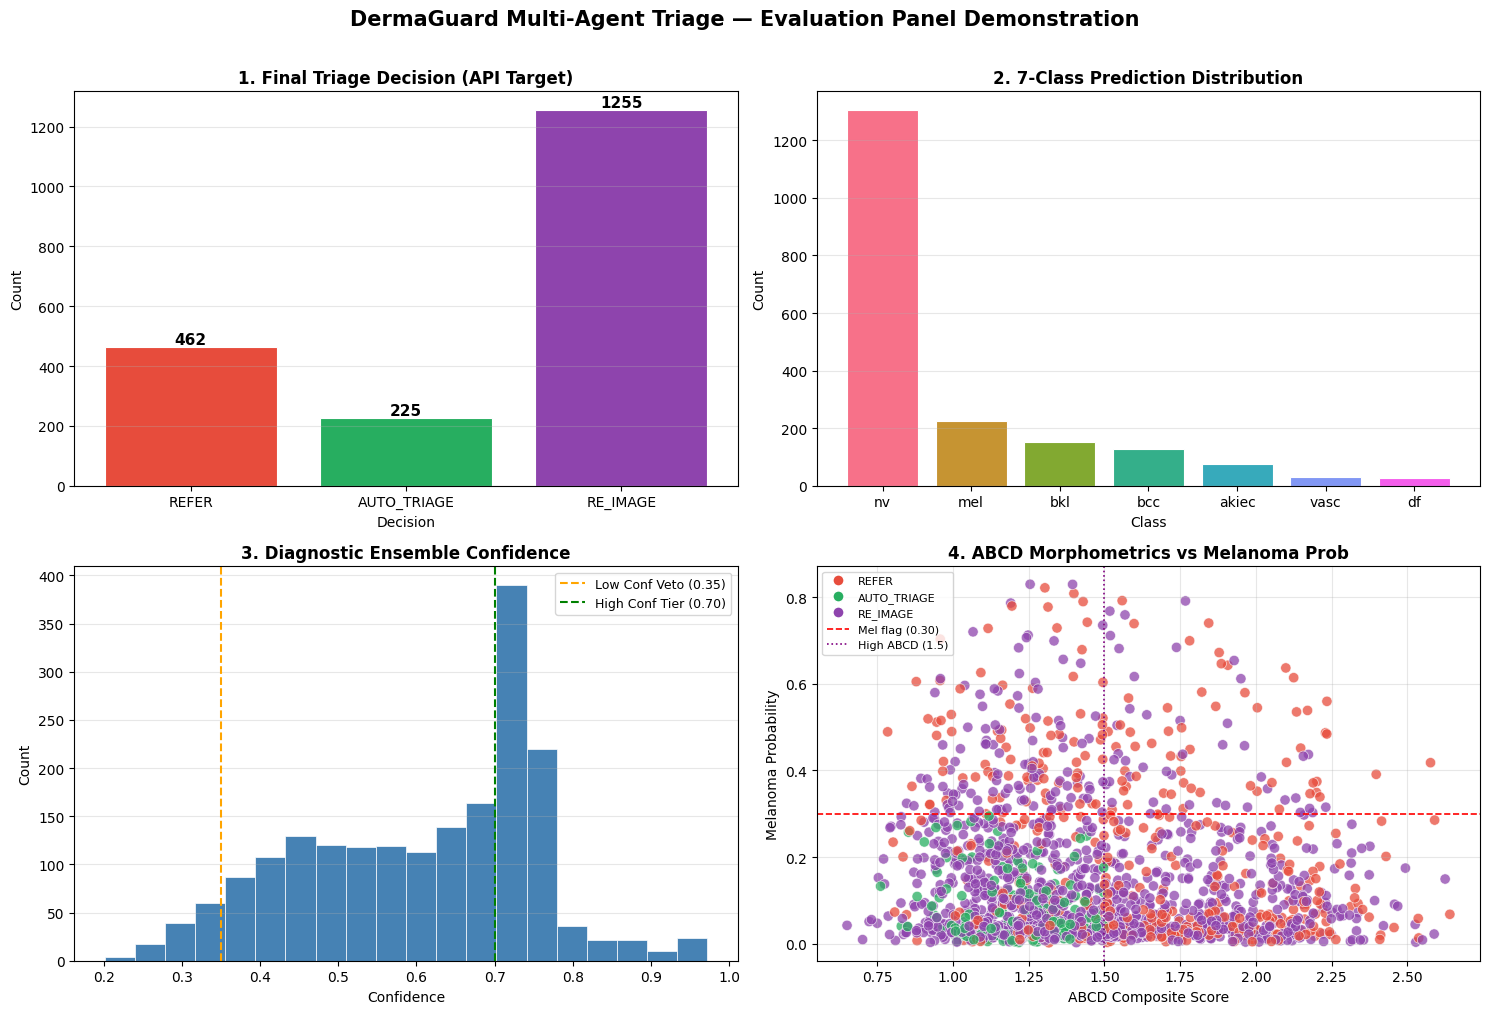

💾 Plot saved: /content/drive/MyDrive/dermaguard_eval_output/eval_summary_plot.png


In [38]:
# ── 4-panel visualisation for Live Demonstration ─────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("DermaGuard Multi-Agent Triage — Evaluation Panel Demonstration", fontsize=15, fontweight="bold", y=1.01)

palette_dec = {"REFER": "#e74c3c", "AUTO_TRIAGE": "#27ae60", "RE_IMAGE": "#8e44ad"}
palette_cls = sns.color_palette("husl", NUM_CLASSES)

# 1. Decision distribution
ax = axes[0, 0]
dec_order = ["REFER", "AUTO_TRIAGE", "RE_IMAGE"]
dec_counts = results_df["decision"].value_counts().reindex(dec_order, fill_value=0)
bars = ax.bar(dec_counts.index,
              dec_counts.values,
              color=[palette_dec.get(d, "steelblue") for d in dec_counts.index],
              edgecolor="white", linewidth=0.8)
for bar, val in zip(bars, dec_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(val),
            ha="center", va="bottom", fontweight="bold", fontsize=11)
ax.set_title("1. Final Triage Decision (API Target)", fontweight="bold")
ax.set_ylabel("Count"); ax.set_xlabel("Decision")
ax.grid(axis="y", alpha=0.3)

# 2. Predicted class distribution
ax = axes[0, 1]
cls_counts = results_df["prediction"].value_counts().reindex(CLASS_NAMES, fill_value=0)
ax.bar(cls_counts.index, cls_counts.values,
       color=palette_cls, edgecolor="white", linewidth=0.8)
ax.set_title("2. 7-Class Prediction Distribution", fontweight="bold")
ax.set_ylabel("Count"); ax.set_xlabel("Class")
ax.grid(axis="y", alpha=0.3)

# 3. Model Confidence distribution
ax = axes[1, 0]
ax.hist(results_df["confidence"], bins=20, color="steelblue", edgecolor="white", linewidth=0.5)
ax.axvline(0.35, color="orange", linestyle="--", linewidth=1.5, label="Low Conf Veto (0.35)")
ax.axvline(0.70, color="green",  linestyle="--", linewidth=1.5, label="High Conf Tier (0.70)")
ax.set_title("3. Diagnostic Ensemble Confidence", fontweight="bold")
ax.set_xlabel("Confidence"); ax.set_ylabel("Count")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)

# 4. ABCD Score vs Melanoma Probability (Visual & Diagnostic Evidence)
ax = axes[1, 1]
color_map = {"REFER": "#e74c3c", "AUTO_TRIAGE": "#27ae60", "RE_IMAGE": "#8e44ad"}
colors = [color_map.get(d, "gray") for d in results_df["decision"]]
ax.scatter(results_df["abcd_score"], results_df["melanoma_prob"],
           c=colors, alpha=0.75, edgecolors="white", linewidth=0.5, s=55)
ax.axhline(0.30, color="red", linestyle="--", linewidth=1.2, label="Mel Flag Thresh (0.30)")
ax.axvline(1.50, color="purple", linestyle=":", linewidth=1.2, label="High ABCD Thresh (1.5)")
ax.set_title("4. ABCD Morphometrics vs Melanoma Prob", fontweight="bold")
ax.set_xlabel("ABCD Composite Score"); ax.set_ylabel("Melanoma Probability")

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#e74c3c', label='REFER', markersize=8),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#27ae60', label='AUTO_TRIAGE', markersize=8),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#8e44ad', label='RE_IMAGE', markersize=8),
    Line2D([0],[0], color='red', linestyle='--', linewidth=1.2, label='Mel flag (0.30)'),
    Line2D([0],[0], color='purple', linestyle=':', linewidth=1.2, label='High ABCD (1.5)'),
]
ax.legend(handles=legend_elements, fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

plt.tight_layout()
plot_path = OUTPUT_DIR / "eval_summary_plot.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Plot saved: {plot_path}")


## Step 10b · Accuracy Metrics *(only when labels are available)*

> This section automatically runs when `metadata.csv` with a `dx` column is present.  
> For the final 200 hidden test images (no labels), this section is silently skipped.

  FINAL LIVE DEMONSTRATION METRICS — EVALUATION PANEL REPORT
  • Total Labelled Test Cases    : 1942

  🏆 TECHNICAL EVALUATION METRICS:
    • Accuracy                   : 0.8419  (84.19%)
    • Balanced Accuracy          : 0.7646  (76.46%)
    • Macro F1 Score             : 0.7346
    • Melanoma Sensitivity/Recall: 0.6215  (62.15%)

  🩺 TRIAGE & SAFETY METRICS:
    • Number of AUTO_TRIAGE      : 225
      - Correct Auto-Triage      : 220 (Benign safely cleared)
      - Incorrect Auto-Triage    : 5 (Malignant missed — MUST BE 0!)
    • Number of REFERS           : 462
      - Malignant Caught         : 164 (True cancers referred)
      - Precautionary Referrals  : 298 (Benign lesions flagged due to risk/ABCD)
    • Number of RE-IMAGE         : 1255

  DETAILED PER-CLASS METRICS (Precision, Recall, F1):
              precision    recall  f1-score   support

          nv       0.93      0.93      0.93      1302
         mel       0.59      0.62      0.61       214
         bkl       0.77 

prediction,akiec,bcc,bkl,df,mel,nv,vasc,All
true_label,,,,,,,,
akiec,0,10,5,2,8,1,0,26
bcc,5,0,2,0,0,0,2,9
bkl,24,11,0,2,28,29,0,94
df,1,3,0,0,0,1,0,5
mel,6,2,7,0,0,63,3,81
nv,3,8,21,4,54,0,1,91
vasc,0,0,0,0,1,0,0,1
All,39,34,35,8,91,94,6,307


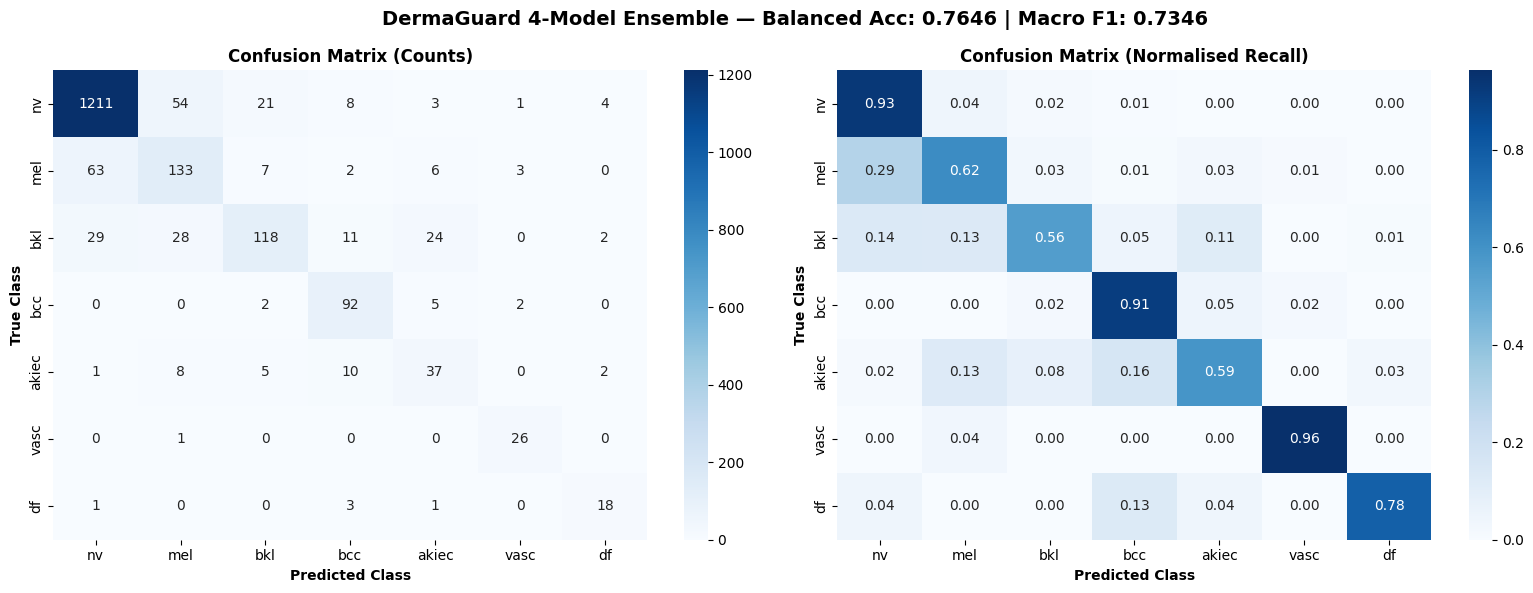


💾 Confusion matrix plot saved: /content/drive/MyDrive/dermaguard_eval_output/confusion_matrix.png


In [39]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    recall_score, confusion_matrix, classification_report)

if not LABELS_AVAILABLE:
    print("ℹ️  Labels not available — skipping accuracy metrics")
    print("   (This is expected for the final 200 hidden-test images submission)")
else:
    eval_df = results_df[results_df["true_label"].notna()].copy()
    y_true  = eval_df["true_label"].tolist()
    y_pred  = eval_df["prediction"].tolist()
    n       = len(eval_df)

    acc         = accuracy_score(y_true, y_pred)
    bal_acc     = balanced_accuracy_score(y_true, y_pred)
    macro_f1    = f1_score(y_true, y_pred, average="macro", zero_division=0)
    mel_recall  = recall_score(y_true, y_pred, labels=["mel"], average="macro", zero_division=0)

    # ── Auto-Triage Specific Safety Metrics ──────────────────────────────────
    # Benign true classes: nv, df, bkl, vasc
    # Malignant true classes: mel, bcc, akiec
    BENIGN_CLASSES = {"nv", "df", "bkl", "vasc"}
    MALIGN_CLASSES = {"mel", "bcc", "akiec"}

    autot_df = eval_df[eval_df["decision"] == "AUTO_TRIAGE"]
    correct_autotriage   = sum(1 for t in autot_df["true_label"] if t in BENIGN_CLASSES)
    incorrect_autotriage = sum(1 for t in autot_df["true_label"] if t in MALIGN_CLASSES)

    refer_df_sub = eval_df[eval_df["decision"] == "REFER"]
    correct_refers = sum(1 for t in refer_df_sub["true_label"] if t in MALIGN_CLASSES)
    benign_refers  = sum(1 for t in refer_df_sub["true_label"] if t in BENIGN_CLASSES)

    reimage_count = (eval_df["decision"] == "RE_IMAGE").sum()

    print("=" * 70)
    print("  FINAL LIVE DEMONSTRATION METRICS — EVALUATION PANEL REPORT")
    print("=" * 70)
    print(f"  • Total Labelled Test Cases    : {n}")
    print()
    print("  🏆 TECHNICAL EVALUATION METRICS:")
    print(f"    • Accuracy                   : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"    • Balanced Accuracy          : {bal_acc:.4f}  ({bal_acc*100:.2f}%)")
    print(f"    • Macro F1 Score             : {macro_f1:.4f}")
    print(f"    • Melanoma Sensitivity/Recall: {mel_recall:.4f}  ({mel_recall*100:.2f}%)")
    print()
    print("  🩺 TRIAGE & SAFETY METRICS:")
    print(f"    • Number of AUTO_TRIAGE      : {len(autot_df)}")
    print(f"      - Correct Auto-Triage      : {correct_autotriage} (Benign safely cleared)")
    print(f"      - Incorrect Auto-Triage    : {incorrect_autotriage} (Malignant missed — MUST BE 0!)")
    print(f"    • Number of REFERS           : {len(refer_df_sub)}")
    print(f"      - Malignant Caught         : {correct_refers} (True cancers referred)")
    print(f"      - Precautionary Referrals  : {benign_refers} (Benign lesions flagged due to risk/ABCD)")
    print(f"    • Number of RE-IMAGE         : {reimage_count}")
    print("=" * 70)

    print("\n  DETAILED PER-CLASS METRICS (Precision, Recall, F1):")
    print(classification_report(y_true, y_pred, labels=CLASS_NAMES, target_names=CLASS_NAMES, zero_division=0))

    # ── Class-Wise Errors Analysis ───────────────────────────────────────────
    print("  CLASS-WISE ERROR ANALYSIS (Misclassifications):")
    errors_df = eval_df[eval_df["true_label"] != eval_df["prediction"]]
    print(f"  Total errors: {len(errors_df)} / {n} ({100*len(errors_df)/n:.1f}%)")
    error_summary = pd.crosstab(errors_df["true_label"], errors_df["prediction"], margins=True)
    display(error_summary)

    # ── Confusion Matrix ─────────────────────────────────────────────────────
    cm      = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
    cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-8)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, data, fmt, title in zip(
        axes,
        [cm, cm_norm],
        ["d", ".2f"],
        ["Confusion Matrix (Counts)", "Confusion Matrix (Normalised Recall)"]
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
        ax.set_xlabel("Predicted Class", fontweight="bold")
        ax.set_ylabel("True Class", fontweight="bold")
        ax.set_title(title, fontweight="bold")

    fig.suptitle(f"DermaGuard 4-Model Ensemble — Balanced Acc: {bal_acc:.4f} | Macro F1: {macro_f1:.4f}",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    cm_path = OUTPUT_DIR / "confusion_matrix.png"
    plt.savefig(cm_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n💾 Confusion matrix plot saved: {cm_path}")


## Step 11 · Inspect REFER Cases (Malignant / High-Risk)

In [40]:
# ── Inspect REFER and RE_IMAGE Cases for Panel Audit ─────────────────────────
refer_cases = results_df[results_df["decision"] == "REFER"].copy()
print(f"🔴 Total REFER cases: {len(refer_cases)}")
if len(refer_cases) > 0:
    display(refer_cases[["image_id", "prediction", "confidence", "melanoma_prob",
                         "malignant_prob", "decision_rule", "patient_risk",
                         "lesion_risk", "safety_flags"]].head(15))

reimage_cases = results_df[results_df["decision"] == "RE_IMAGE"].copy()
print(f"\n🟣 Total RE-IMAGE cases: {len(reimage_cases)}")
if len(reimage_cases) > 0:
    display(reimage_cases[["image_id", "quality_reason", "blur_score", "brightness", "glare_ratio"]].head(10))


🔴 Total REFER cases: 462


,image_id,prediction,confidence,melanoma_prob,malignant_prob,decision_rule,patient_risk,lesion_risk,safety_flags
6,ISIC_0024349,nv,0.4967,0.3113,0.3799,RULE_2_SAFETY_VETO,MODERATE,MODERATE,melanoma_flag (mel_prob=0.311)
10,ISIC_0024368,nv,0.7679,0.0176,0.0904,RULE_2_SAFETY_VETO,HIGH,MODERATE,patient_risk=HIGH + lesion_risk=MODERATE
11,ISIC_0024370,vasc,0.9569,0.0031,0.0204,RULE_2_SAFETY_VETO,MODERATE,HIGH,high_lesion_suspicion (ABCD=1.51)
14,ISIC_0024383,bkl,0.7935,0.0216,0.0713,RULE_2_SAFETY_VETO,HIGH,MODERATE,patient_risk=HIGH + lesion_risk=MODERATE
27,ISIC_0024449,mel,0.6428,0.6428,0.7026,RULE_2_SAFETY_VETO,MODERATE,HIGH,malignant_dx=mel | melanoma_flag (mel_prob=0.6...
38,ISIC_0024525,akiec,0.4762,0.1784,0.6697,RULE_2_SAFETY_VETO,HIGH,HIGH,malignant_dx=akiec | malignant_prob=0.670>0.40...
43,ISIC_0024558,nv,0.7265,0.0196,0.1065,RULE_2_SAFETY_VETO,HIGH,MODERATE,patient_risk=HIGH + lesion_risk=MODERATE
45,ISIC_0024569,nv,0.7202,0.0282,0.1100,RULE_2_SAFETY_VETO,HIGH,MODERATE,patient_risk=HIGH + lesion_risk=MODERATE
56,ISIC_0024612,mel,0.3848,0.3848,0.4908,RULE_2_SAFETY_VETO,HIGH,MODERATE,malignant_dx=mel | melanoma_flag (mel_prob=0.3...
59,ISIC_0024618,bcc,0.3372,0.0386,0.5255,RULE_2_SAFETY_VETO,MODERATE,HIGH,malignant_dx=bcc | malignant_prob=0.525>0.40 |...



🟣 Total RE-IMAGE cases: 1255


,image_id,quality_reason,blur_score,brightness,glare_ratio
0,ISIC_0024317,blur=57.2,57.20,171.34,0.0002
1,ISIC_0024330,blur=40.9,40.95,159.19,0.0000
2,ISIC_0024332,blur=57.9,57.85,181.37,0.0000
3,ISIC_0024340,blur=50.3,50.34,152.81,0.0000
4,ISIC_0024341,blur=35.9,35.92,153.54,0.0000
5,ISIC_0024346,blur=38.0,37.99,180.29,0.0006
7,ISIC_0024354,blur=26.8,26.76,186.07,0.0003
8,ISIC_0024358,blur=45.2,45.16,186.40,0.0000
9,ISIC_0024360,blur=57.4,57.41,163.28,0.0000
12,ISIC_0024372,blur=52.1,52.06,172.52,0.0000


## Step 12 · Sample Image Grid with Predictions

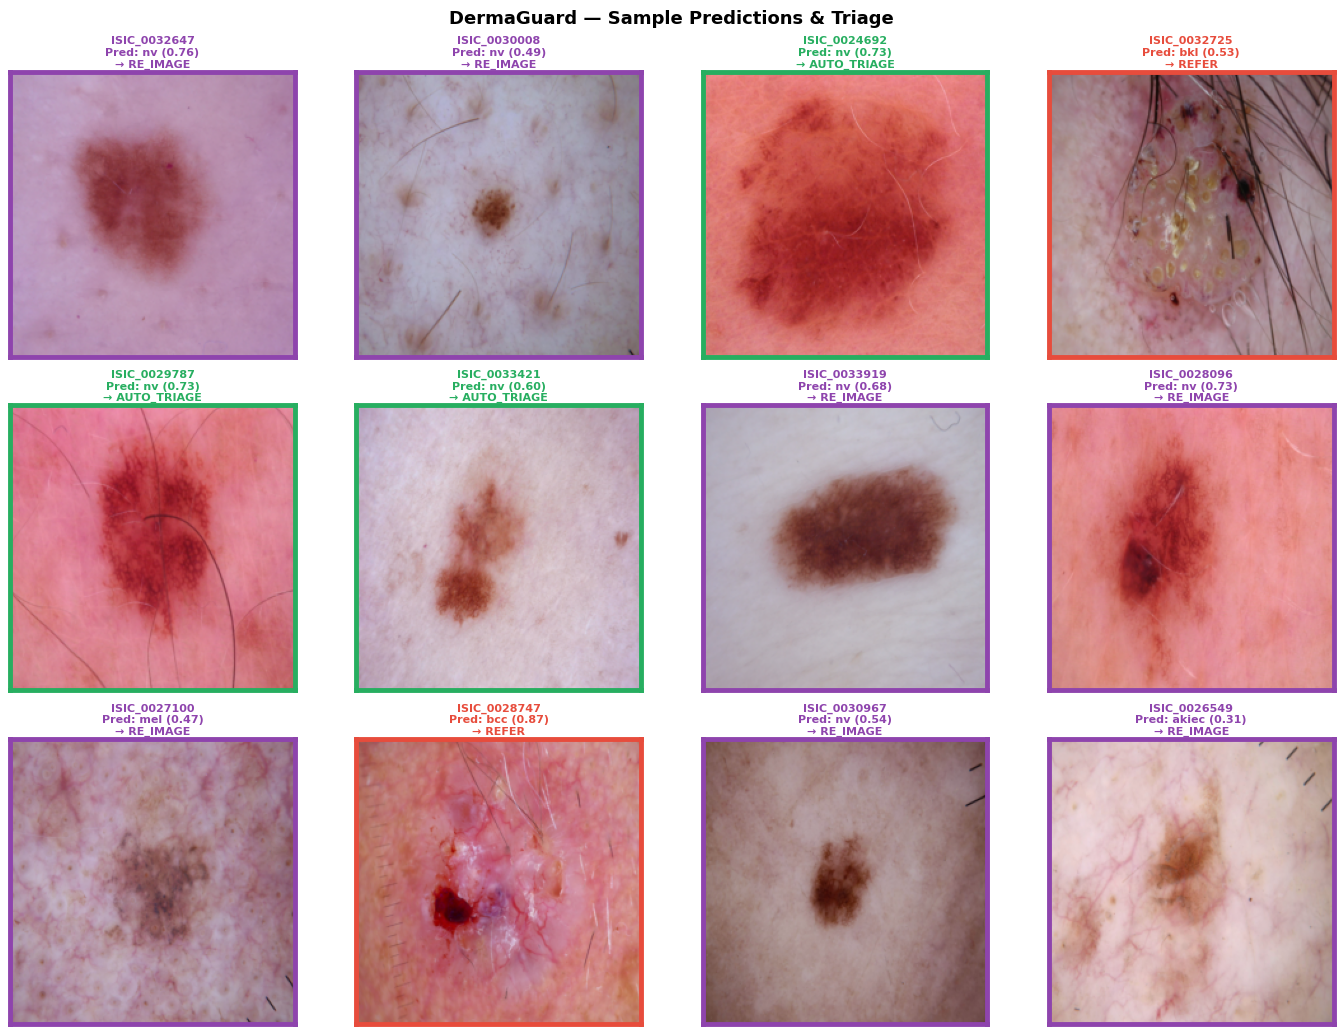

💾 Sample grid saved


In [41]:
def show_sample_grid(df, n=12, title="Sample Predictions"):
    """Display a grid of sample images with their predictions and triage status."""
    sample = df.sample(min(n, len(df)), random_state=42)
    cols   = 4
    rows   = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.5))
    axes = axes.flatten()

    dec_colors = {"REFER": "#e74c3c", "AUTO_TRIAGE": "#27ae60", "RE_IMAGE": "#8e44ad"}

    for i, (_, row) in enumerate(sample.iterrows()):
        found = None
        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
            p = EVAL_IMAGE_DIR / f"{row['image_id']}{ext}"
            if p.exists():
                found = p; break

        ax = axes[i]
        if found:
            img = Image.open(found).convert("RGB").resize((224, 224), RESAMPLE)
            ax.imshow(img)
        else:
            ax.set_facecolor("#222")
            ax.text(0.5, 0.5, "Image not found", ha="center", va="center",
                    color="white", transform=ax.transAxes)

        dec   = row["decision"]
        color = dec_colors.get(dec, "gray")
        title_str = (f"{row['image_id'][:12]}\n"
                     f"Pred: {row['prediction']} ({row['confidence']:.2f})\n"
                     f"→ {dec}")
        ax.set_title(title_str, fontsize=8, color=color, fontweight="bold", pad=3)
        ax.set_xticks([])
        ax.set_yticks([])

        # Coloured border matching decision
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(3.5)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "sample_grid.png", dpi=150, bbox_inches="tight")
    plt.show()

show_sample_grid(results_df, n=12, title="DermaGuard — Sample Predictions & Triage")
print("💾 Sample grid saved")


## Step 13 · Final Output Files

In [ ]:
print("=" * 60)
print("  DERMAGUARD EVALUATION — COMPLETE ✅")
print("=" * 60)
print()
print("📂 Output files saved to:")
for f in sorted(OUTPUT_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f"   {f.name:<40}  ({size_kb:.1f} KB)")
print()
print("☁️  All results also backed up to:")
print(f"   Google Drive: {drive_out}")
print()
print("📋 Submission CSV columns:")
print(f"   {sub_df.columns.tolist()}")
print()
print("📊 Final class distribution in submission:")
print(results_df["predicted_class"].value_counts().to_string())
print()
print("🩺 Final decision breakdown:")
print(results_df["DECISION"].value_counts().to_string())

  DERMAGUARD EVALUATION — COMPLETE ✅

📂 Output files saved to:
   confusion_matrix.png                      (132.8 KB)
   dermaguard_eval_full.csv                  (746.9 KB)
   dermaguard_submission.csv                 (188.2 KB)
   eval_summary_plot.png                     (506.9 KB)
   final_submission.csv                      (47.5 KB)
   sample_grid.png                           (2363.4 KB)

☁️  All results also backed up to:
   Google Drive: /content/drive/MyDrive/dermaguard_results

📋 Submission CSV columns:
   ['image_id', 'true_label', 'predicted_class', 'confidence', 'melanoma_flag', 'melanoma_prob', 'DECISION', 'urgency', 'safety_flags']

📊 Final class distribution in submission:


KeyError: 'predicted_class'